In [1]:
import os, glob, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})

V4 = os.path.abspath("../../terrawatch-datasets")     # the dataset folder (sits next to this repository)
DS = V4 + "/dataset"                                       # built datasets
RAW = V4 + "/inputs_raw"                                   # raw downloads, exactly as they arrived
START = pd.Timestamp("2019-01-01")                         # day 0 of the cube; day t = START + t days

# 02. Forest boundaries and the grid of cells

**Question this answers:** what is a "forest cell", and how did we choose which ones to keep?

We do **not** use tree cover from a satellite map to decide what is forest. We use **legal forest land**:
the official boundaries of reserved and protected forest. A cell is kept if at least **20%** of its area lies inside those boundaries.

## 1. Raw: three official boundary layers

In [2]:
lay = {}
for name in ["Bharatmaps_RFA", "SOI_Forests", "FSI_Divisions"]:
    g = pd.read_parquet(f"{DS}/fsi_boundaries/{name}.parquet", columns=None)
    lay[name] = g
    print(f"{name:16s} {len(g):7d} polygons   columns: {', '.join([c for c in g.columns if c != 'geometry'][:8])} ...")

Bharatmaps_RFA    422197 polygons   columns: objectid, name, name_of_rf, division, range, ownership, block, comp_no ...


SOI_Forests        57963 polygons   columns: OBJECTID_1, objectid, unique_id, survey_dat, fcode, type, tree_type, addl_info ...


FSI_Divisions      92981 polygons   columns: OBJECTID, Division, Circle_Nam, ST_Name, ST_Code, Div_code, Cir_code, Shape_Length ...


In [3]:
# Bharatmaps_RFA = reserved forest areas;  FSI_Divisions = forest divisions;  SOI_Forests = Survey of India forest polygons
rfa = lay["Bharatmaps_RFA"]
print("reserved forest polygons per state (top 12):")
rfa.st_name.value_counts().head(12).to_frame("polygons")

reserved forest polygons per state (top 12):


,polygons
st_name,
JHARKHAND,141833
MAHARASHTRA,45214
GUJARAT,39757
MADHYA PRADESH,39438
WEST BENGAL,32027
CHHATTISGARH,25751
HIMACHAL PRADESH,17703
UTTARAKHAND,17686
UTTAR PRADESH,11725


These are *polygons* (the shape of each forest patch). They are stored as geometry, which is slow to test point by point,
so we turned the union of two layers (reserved forest + Survey of India forest) into a **picture of 0 and 1** once.

## 2. The forest mask

mask shape: (29000, 30000)  rows run from lat 35.0 downward, columns from lon 68.0 eastward


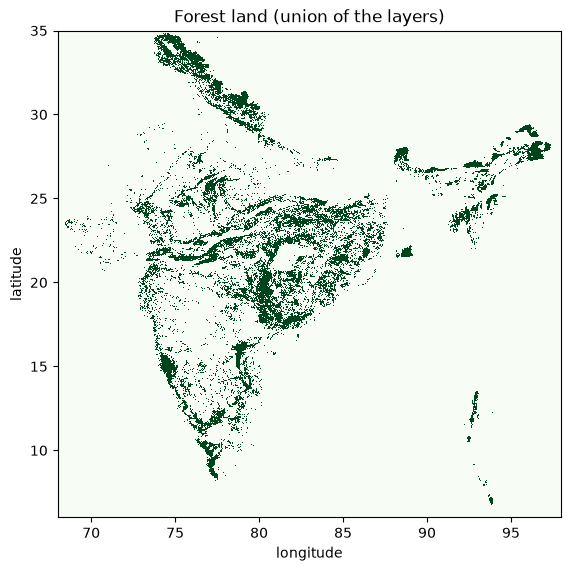

share of the mask that is forest land (sampled): 6.8 %


In [4]:
mask = np.load(f"{DS}/forest_union_0p001.npy", mmap_mode="r")     # 1 pixel = 0.001 degree (about 110 m)
print("mask shape:", mask.shape, " rows run from lat 35.0 downward, columns from lon 68.0 eastward")
small = np.asarray(mask[::25, ::25])                                # look at every 25th pixel only
plt.figure(figsize=(6.5, 6.5)); plt.imshow(small, extent=[68, 98, 6, 35], cmap="Greens", interpolation="nearest"); plt.title("Forest land (union of the layers)")
plt.xlabel("longitude"); plt.ylabel("latitude"); plt.grid(False); plt.show()
print("share of the mask that is forest land (sampled):", round(100 * small.mean(), 2), "%")

## 3. The grid: cells of 0.1 degree

In [5]:
cells = pd.read_parquet(f"{DS}/forest_all/cells.parquet")
print(len(cells), "forest cells in the training table.  One cell is about 11 km x 11 km (110 km2).")
cells[["cell_id", "state", "lat", "lon", "forest_land_frac", "set", "cell_idx"]].head(5)

7148 forest cells in the training table.  One cell is about 11 km x 11 km (110 km2).


,cell_id,state,lat,lon,forest_land_frac,set,cell_idx
0,157741,MH,15.7,74.1,0.2856,six,0
1,158740,MH,15.8,74.0,0.2310,six,1
2,158741,MH,15.8,74.1,0.3868,six,2
3,158742,MH,15.8,74.2,0.8094,six,3
4,158743,MH,15.8,74.3,0.6366,six,4


`cell_id = lat_index * 1000 + lon_index` with `index = round(coordinate * 10)`. Example: latitude 15.7, longitude 74.1 gives `157741`.
`cell_idx` is just the position of the cell in our tables (0 to 7147). The cube uses this position.

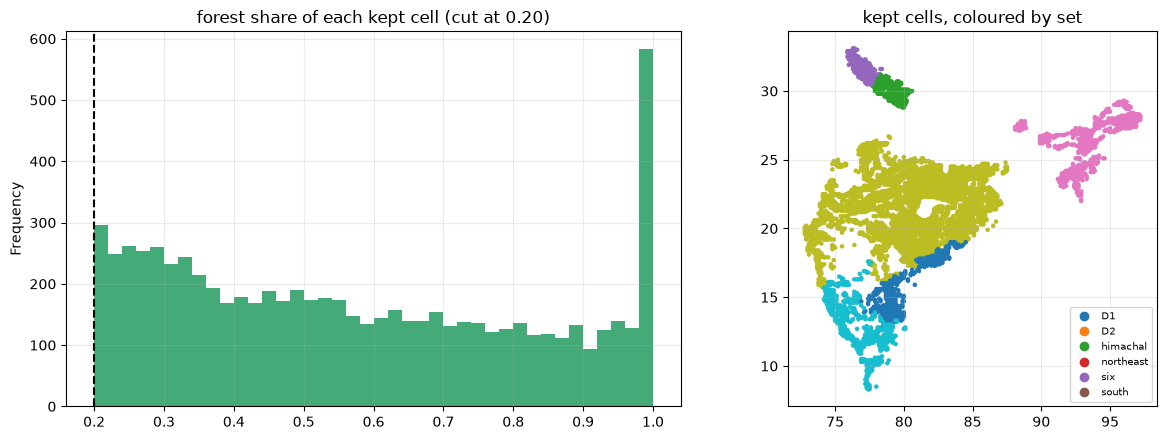

{'D1': 518, 'D2': 310, 'himachal': 239, 'northeast': 766, 'six': 4588, 'south': 727}


In [6]:
# forest_land_frac = the share of the 100 x 100 mask pixels of the cell that are forest land
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
cells.forest_land_frac.plot.hist(bins=40, ax=ax[0], color="#4a7"); ax[0].axvline(0.2, color="k", ls="--"); ax[0].set_title("forest share of each kept cell (cut at 0.20)")
col = {s: i for i, s in enumerate(sorted(cells.set.unique()))}
sc = ax[1].scatter(cells.lon, cells.lat, c=cells.set.map(col), s=5, cmap="tab10"); ax[1].set_title("kept cells, coloured by set"); ax[1].set_aspect("equal")
ax[1].legend(handles=[plt.Line2D([], [], marker="o", ls="", color=plt.cm.tab10(i / 9), label=s) for s, i in col.items()], fontsize=7)
plt.tight_layout(); plt.show()
print(cells.groupby("set").size().to_dict())

Everything with less than 20% forest is not in the dataset at all. We do not predict for fields, towns or deserts.
Cells in Meghalaya and Nagaland were left out, and the blind states (UP, West Bengal, Kerala) are kept separately.

## 4. Neighbours

neighbours that exist, out of 25 (the cell itself counts): average 16.8
cells with all 25: 563 of 7148 (8%)
cells with all 8 touching neighbours: 2034 of 7148


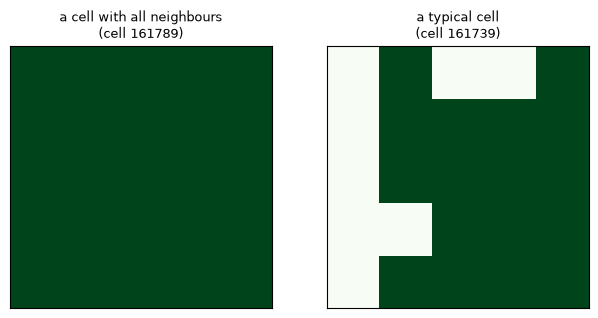

In [7]:
import sys; sys.path.insert(0, os.path.abspath("../src"))
from src import patches
nbr = patches.neighbour_table(cells)               # for every cell: the 25 cells of its 5 x 5 neighbourhood (-1 = no such cell in the dataset)
have = (nbr >= 0).sum(1)
print("neighbours that exist, out of 25 (the cell itself counts): average", round(have.mean(), 1))
print("cells with all 25:", int((have == 25).sum()), "of", len(cells), f"({100 * (have == 25).mean():.0f}%)")
inner = [(di + 2) * 5 + (dj + 2) for di in (-1, 0, 1) for dj in (-1, 0, 1)]          # the 3 x 3 block in the middle of the 5 x 5
print("cells with all 8 touching neighbours:", int(((nbr[:, inner] >= 0).all(1)).sum()), "of", len(cells))

i = int(np.where(have == 25)[0][0])          # first cell that has all 25
j = int(np.argmin(np.abs(have - np.median(have))))     # a cell with a typical number of neighbours
fig, ax = plt.subplots(1, 2, figsize=(7.5, 3.4))
for a, k, title in [(ax[0], i, "a cell with all neighbours"), (ax[1], j, "a typical cell")]:
    a.imshow((nbr[k] >= 0).reshape(5, 5), cmap="Greens", vmin=0, vmax=1); a.set_title(title + f"\n(cell {int(cells.cell_id[k])})", fontsize=9); a.grid(False); a.set_xticks([]); a.set_yticks([])
plt.show()

Green = the neighbour exists in our dataset; white = it is not a forest cell (or is outside India). The models read this 5 x 5 patch. Missing neighbours are filled with zeros and flagged,
so the model can tell the difference between "zero" and "nothing here".

**Ring features:** `nonforest_land_ring8` and `crop_ring8` are the average non-forest and crop share of the 8 nearest neighbouring cells. They tell the model
whether the forest is a big block or a small patch next to farms.

## 5. What is missing or weak here

- The mask is **one snapshot in time**. Forest that was cleared, burned or planted between 2019 and 2025 is not tracked.
- Legal forest land is not the same as dense forest: some of it is open or degraded land.
- At 11 km the cell is big. A cell can hold 30% forest, 50% farm and a village, and its weather is the same for the whole cell.
- Forest is patchy: few cells have all 8 touching neighbours, and a full 5 x 5 patch is rare (counts above). The patch is often half empty.
- The list of kept cells depends on the 0.20 cut. Other cuts (0.30, 0.50) were tested as sensitivity checks in the v4 audit.